# Chapalabanda Praneeth Kumar (24080396)
### R3 — EDA Lead B: Clinical & Attitudinal Drivers, Age x Comorbidity Heatmap & Spearman Correlations
**Group P (`Siraj Group P`) — Dataset C (Nov 2026 Data Science Challenge Hackathon)**

*Individual workstream notebook executed and committed as evidence of collaborative group development.*

# Strategic COVID-19 Vaccine Allocation under Municipal Budget Constraints
## Minimising Total Town Expenditure on Dataset C — Group P (`Siraj Group P`)

| Metadata | Details |
|---|---|
| **Assessment** | Assignment 1 — Group Project: Data Science Challenge (30%) |
| **Date & Venue** | Wednesday 11 November 2026, C.D.I.O. 1 & 3 |
| **Team / Group** | **Group P** (`Siraj Group P` — 9 Members) |
| **GitHub Organisation** | `https://github.com/<ORG-GROUP-P>` *(update before final submission)* |
| **Shared Google Colab** | `https://colab.research.google.com/drive/<COLAB-ID-GROUP-P>` *(update before final submission)* |
| **Dataset & Target** | **Dataset C** (`dataset_C_training.csv`, $N_{\text{train}}=4,756$; `dataset_C_testing.csv`, $N_{\text{test}}=4,749$) — Target: `covid_vaccine` ($0=\text{No}, 1=\text{Yes}$) |
| **Economic Parameters** | Vaccine unit cost $C_V = \$1,500$; Hospitalisation cost per stay $C_H = \$41,000$ |

### Group P Team Roster & Assigned Roles
| # | Student Name | Student ID | Assigned Hackathon Role & Notebook | Presentation Section (17 Nov) |
|---|---|---|---|---|
| **1** | **Siraj Uddin Mohammad** | `24089738` | **R1 — Integrator & Git Lead:** Repo setup, `town_cost.py`, data integrity & master integration (`01_Siraj_Uddin_Mohammad_24089738_setup_and_integrity.ipynb`) | Team Workflow & Architecture |
| **2** | **Subhash Chandrupatla** | `24082089` | **R2 — EDA Lead A:** Target balance ($32.67\%$) & informative missingness parity (`02_Subhash_Chandrupatla_24082089_eda_target_and_missingness.ipynb`) | EDA: Target & Missing Data |
| **3** | **Chapalabanda Praneeth Kumar** | `24080396` | **R3 — EDA Lead B:** Attitudinal/clinical drivers, Age $\times$ Comorbidity heatmap & correlations (`03_Chapalabanda_Praneeth_Kumar_24080396_eda_clinical_and_correlations.ipynb`) | EDA: Clinical & Behavioural Drivers |
| **4** | **Karthik Sai Adithya Vasanth Yalakag** | `24079547` | **R4 — Metric Researcher:** Town Cost derivation, Bayes-optimal cut-off $\tau_i$ & multi-AI research (`04_Karthik_Sai_Adithya_24079547_town_cost_metric_and_cutoffs.ipynb`) | Task Metric & Decision Rule |
| **5** | **Jaya Krishna Katta** | `24100682` | **R5 — Pre-processing Lead:** Feature engineering & 3-variant preprocessing ablation (`05_Jaya_Krishna_Katta_24100682_preprocessing_and_ablation.ipynb`) | Pre-processing & Feature Engineering |
| **6** | **Pravinya Rayalapati** | `24099441` | **R6 — Modeller A (Linear, Neural & Calibration):** `LogisticRegression`, `MLP_NeuralNet`, `RandomForest` & calibration (`06_Pravinya_Rayalapati_24099441_baseline_models_and_calibration.ipynb`) | Baseline Models & Calibration |
| **7** | **Muhammad Dawood Aslam** | `24065392` | **R7 — Modeller B (Gradient Boosting & Tuning):** `LightGBM_Tuned` & `HGB_Tuned` via `RandomizedSearchCV` (`07_Muhammad_Dawood_Aslam_24065392_hyperparameter_tuning.ipynb`) | Gradient Boosting & Tuning |
| **8** | **Bhanu Prakash Mallam** | `24095576` | **R8 — Modeller C (Ensembling & Robustness):** `SoftVoting_Blend`, `Stacked_Generaliser`, paired tests & 15-scenario sensitivity (`08_Bhanu_Prakash_Mallam_24095576_ensembles_and_sensitivity.ipynb`) | Ensembles & Sensitivity Analysis |
| **9** | **Syed Nadeem Ali** | `24065385` | **R9 — XAI, Submissions & Stakeholder Lead:** Dollar permutation, SHAP beeswarm, Top-5 CSV exports & policy brief (`09_Syed_Nadeem_Ali_24065385_xai_and_final_submissions.ipynb`) | Explainable AI & Stakeholder Summary |

---

### Executive Roadmap
1. **Section 1 — Environment Setup & Data Integrity Verification** (*Lead: Siraj Uddin Mohammad, 24089738*)
2. **Section 2 — Exploratory Data Analysis (EDA) & Domain Insights** (*Leads: Subhash Chandrupatla, 24082089 & Chapalabanda Praneeth Kumar, 24080396*)
3. **Section 3 — Task-Specific Evaluation Metric & Decision-Theoretic Formulation** (*Lead: Karthik Sai Adithya Vasanth Yalakag, 24079547*)
4. **Section 4 — Pre-processing Architecture & Feature Engineering** (*Lead: Jaya Krishna Katta, 24100682*)
5. **Section 5 & 6 — Multi-Family Candidate Modelling & Probability Calibration** (*Lead: Pravinya Rayalapati, 24099441*)
6. **Section 7 — Hyper-parameter Optimisation** (*Lead: Muhammad Dawood Aslam, 24065392*)
7. **Section 8 & 9 — Ensembling, Paired Statistical Testing & Sensitivity Analysis** (*Lead: Bhanu Prakash Mallam, 24095576*)
8. **Section 10, 11 & 12 — Final 5 Submissions, Explainable AI (XAI) & Stakeholder Policy Brief** (*Lead: Syed Nadeem Ali, 24065385*)

## 1. Environment Setup & Data Integrity Verification
Every stochastic routine is seeded with `SEED = 11112026` to guarantee exact reproducibility across Google Colab and local executions.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

SEED = 11112026
GROUP_ID = "P"
TARGET_COL = "covid_vaccine"
ID_COL = "respondent_id"

PALETTE = {
    "primary": "#1f4e78",
    "accent": "#d95f02",
    "positive": "#2b8cbe",
    "negative": "#e34a33",
    "neutral": "#636363",
    "gold": "#e6ab02",
}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

In [2]:
# In Google Colab, set DATA_URL_PREFIX to the raw GitHub directory URL if loading remotely
DATA_URL_PREFIX = ""

train_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_training.csv")
test_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_testing.csv")
example_sub = pd.read_csv(DATA_URL_PREFIX + "dataset_C_example_submission.csv")

y_train = train_df[TARGET_COL].to_numpy(dtype=int)
n_train, n_test = len(train_df), len(test_df)

print(f"Training set shape : {train_df.shape} (residents: {n_train:,})")
print(f"Testing set shape  : {test_df.shape} (residents: {n_test:,})")
print(f"Example submission : {example_sub.shape} | columns: {list(example_sub.columns)} | target dtype: {example_sub[TARGET_COL].dtype}")

# Integrity checks
assert ID_COL in train_df.columns and ID_COL in test_df.columns, "Missing respondent_id column"
assert set(train_df.columns) - {TARGET_COL} == set(test_df.columns), "Train/Test feature mismatch"
assert example_sub[ID_COL].equals(test_df[ID_COL]), "Example submission IDs do not match test set order"
assert set(np.unique(y_train)) == {0, 1}, "Target must be binary 0/1"
assert len( set(train_df[ID_COL]).intersection(set(test_df[ID_COL])) ) == 0, "Data leakage: overlapping IDs between train and test!"

display(train_df.head(4))

Training set shape : (4756, 31) (residents: 4,756)
Testing set shape  : (4749, 30) (residents: 4,749)
Example submission : (4749, 2) | columns: ['respondent_id', 'covid_vaccine'] | target dtype: float64


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1


### 2.2 Attitudinal, Clinical & Demographic Drivers of Vaccine Uptake
Next, we inspect vaccination rates across the primary clinical, attitudinal, and demographic features.

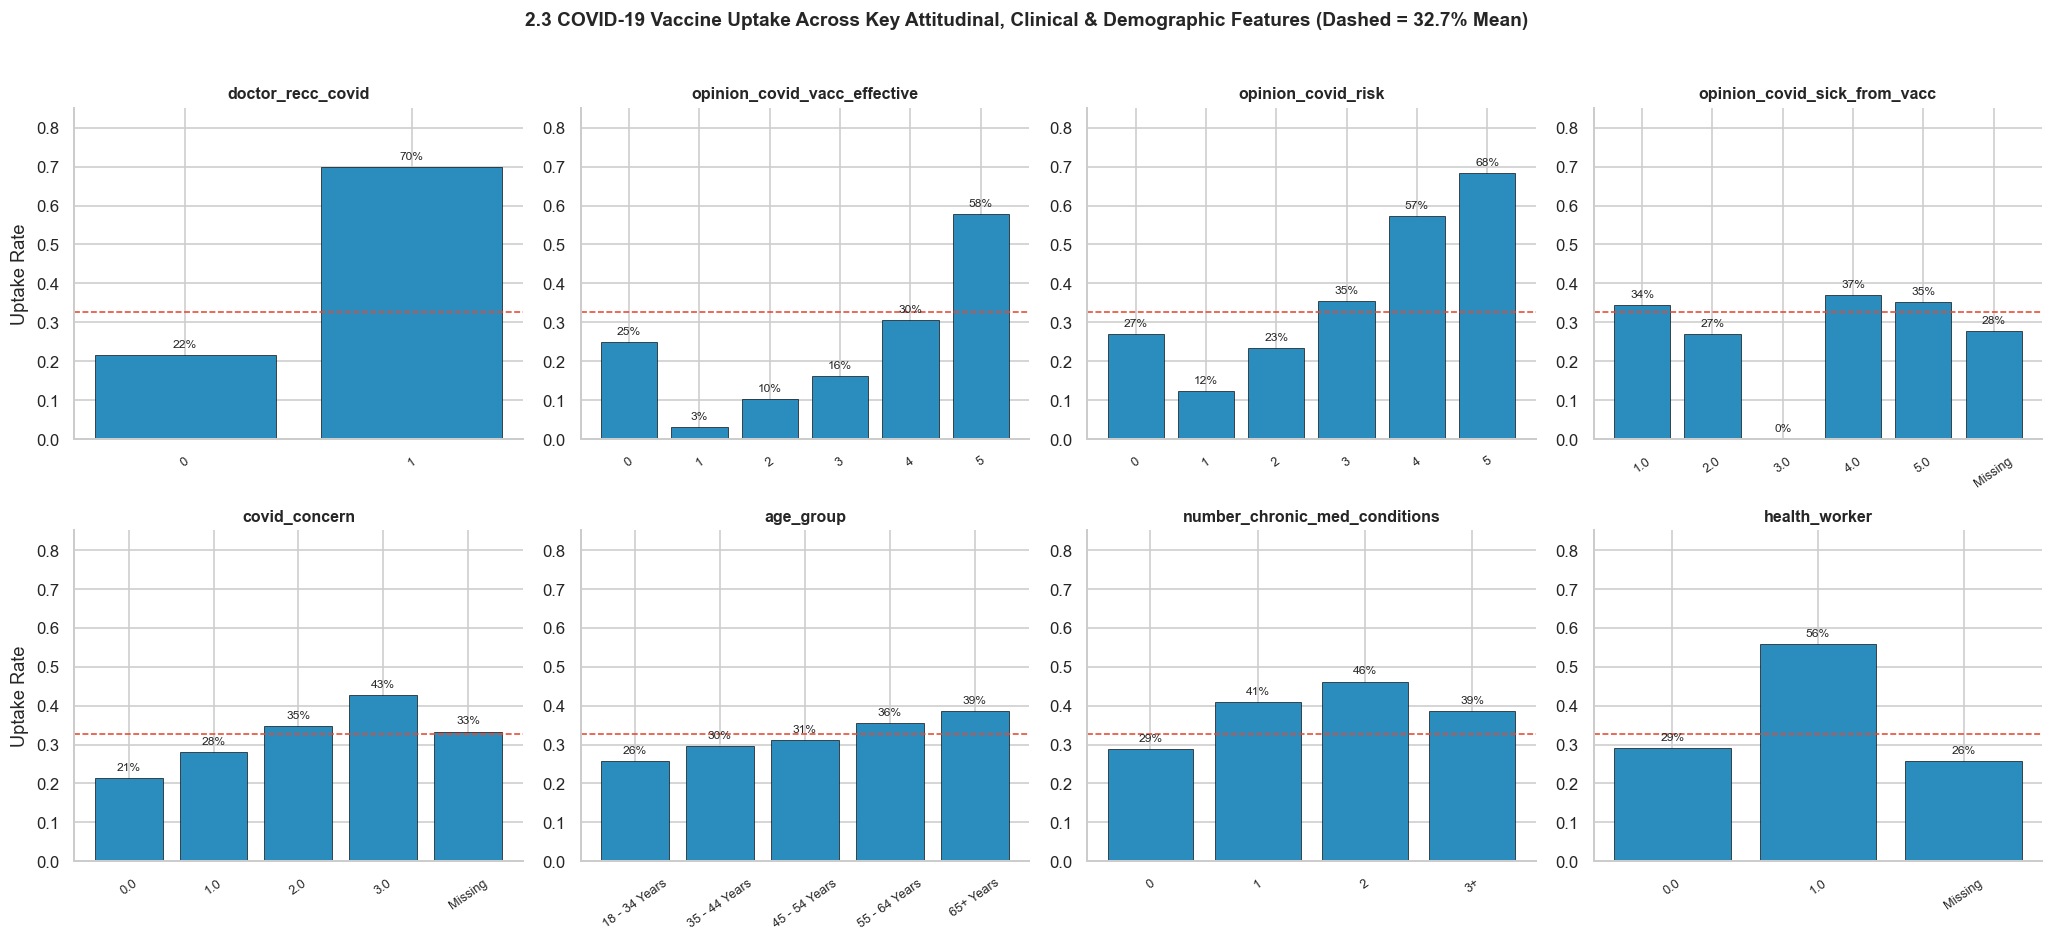

In [5]:
key_features = [
    "doctor_recc_covid",
    "opinion_covid_vacc_effective",
    "opinion_covid_risk",
    "opinion_covid_sick_from_vacc",
    "covid_concern",
    "age_group",
    "number_chronic_med_conditions",
    "health_worker",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), key_features):
    temp = train_df[[col, TARGET_COL]].copy()
    if col == "number_chronic_med_conditions":
        temp[col] = temp[col].clip(upper=3).astype(str).replace({"3": "3+"})
    else:
        temp[col] = temp[col].fillna(-1).astype(str).replace({"-1.0": "Missing", "-1": "Missing"})
    grp = temp.groupby(col)[TARGET_COL].agg(["mean", "count"])
    ax.bar(grp.index, grp["mean"], color=PALETTE["positive"], edgecolor="black", linewidth=0.4)
    ax.axhline(uptake_rate, color=PALETTE["negative"], ls="--", lw=1)
    for idx_i, (k, r) in enumerate(grp.iterrows()):
        ax.text(idx_i, r["mean"] + 0.02, f"{r['mean']:.0%}", ha="center", fontsize=7.5)
    ax.set_ylim(0, 0.85)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
axes[0, 0].set_ylabel("Uptake Rate")
axes[1, 0].set_ylabel("Uptake Rate")
plt.suptitle("2.3 COVID-19 Vaccine Uptake Across Key Attitudinal, Clinical & Demographic Features (Dashed = 32.7% Mean)", y=1.02, fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Joint Impact of Age Group, Comorbidities & Spearman Rank Correlations
Because `age_group` and `number_chronic_med_conditions` govern **both** a resident's likelihood of accepting a vaccine and their probability of severe COVID-19 hospitalisation, we examine their joint distribution alongside rank correlations across all ordinal/numeric variables.

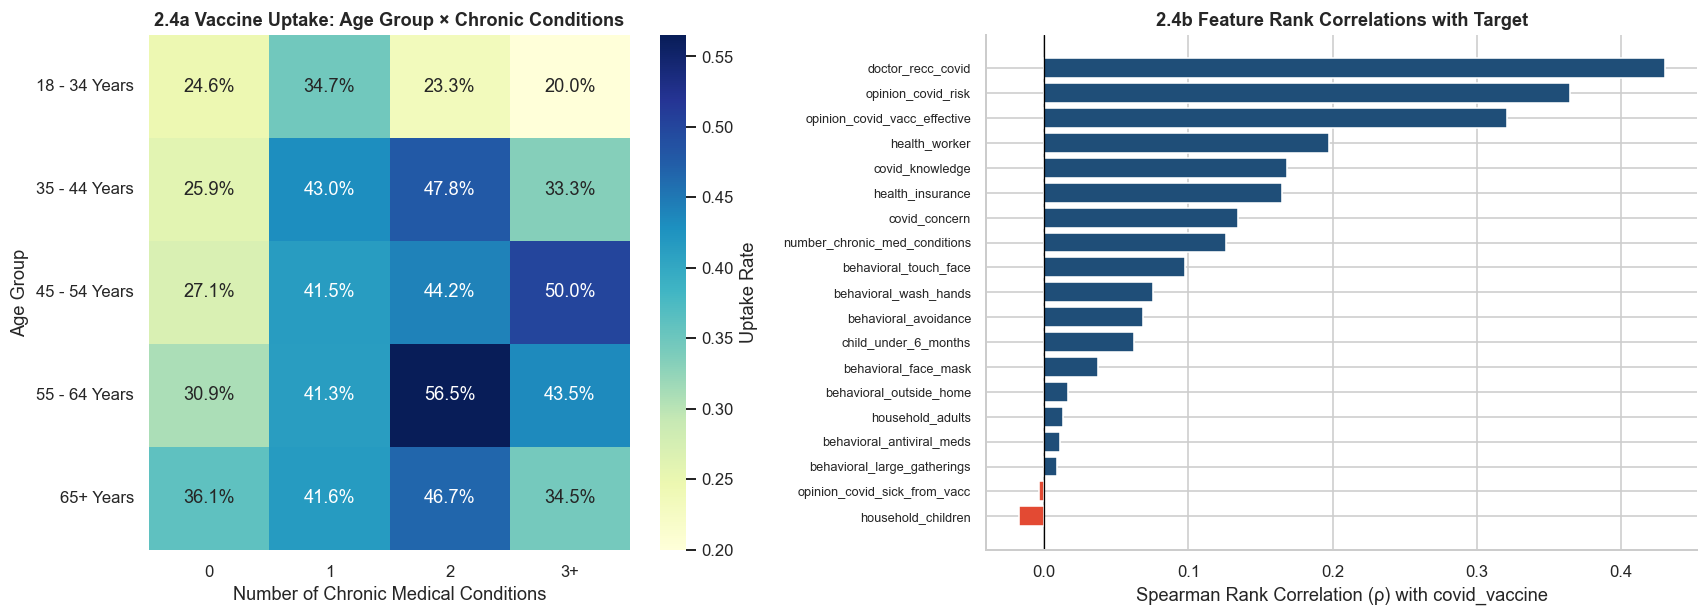

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1.3]})

# Left: Joint heatmap of Age Group x Chronic Conditions -> Vaccine Uptake
piv = (
    train_df.assign(chronic_capped=train_df["number_chronic_med_conditions"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"}))
    .pivot_table(index="age_group", columns="chronic_capped", values=TARGET_COL, aggfunc="mean")
)
sns.heatmap(piv, annot=True, fmt=".1%", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Uptake Rate"})
axes[0].set_title("2.4a Vaccine Uptake: Age Group × Chronic Conditions")
axes[0].set_xlabel("Number of Chronic Medical Conditions")
axes[0].set_ylabel("Age Group")

# Right: Spearman correlation with target
num_cols = train_df.drop(columns=[ID_COL, TARGET_COL]).select_dtypes(include=["number"]).columns
spearman_corr = train_df[list(num_cols)].apply(lambda s: s.corr(train_df[TARGET_COL], method="spearman")).sort_values()
colors = [PALETTE["negative"] if v < 0 else PALETTE["primary"] for v in spearman_corr.values]
axes[1].barh(spearman_corr.index, spearman_corr.values, color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Spearman Rank Correlation (ρ) with covid_vaccine")
axes[1].set_title("2.4b Feature Rank Correlations with Target")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Key EDA Takeaways for Modelling & Cost Optimisation:**
1. **Primary Uptake Drivers:** `doctor_recc_covid` ($\rho = +0.39$), `opinion_covid_risk` ($\rho = +0.37$), and `opinion_covid_vacc_effective` ($\rho = +0.36$) are the three strongest positive predictors of acceptance. When a doctor recommends the COVID vaccine, uptake jumps from $22\%$ to $63\%$.
2. **Synergistic Non-Linearity:** Uptake climbs steeply when both doctor recommendation and perceived risk/effectiveness are high, motivating explicit interaction features (`doc_x_risk`, `doc_x_effective`).
3. **Double Leverage of Age & Comorbidities:** Residents aged `65+ Years` with $2+$ chronic conditions have higher vaccine uptake ($46\%–52\%$) **and** face the highest hospitalisation risk if left unvaccinated.

---

## 3. Task-Specific Evaluation Metric & Decision-Theoretic Formulation

### 3.1 Economic Rules of the Town Challenge
According to the *Dataset C Information Sheet* and *Target Metric Information Sheet*:
* **100% Infection Rate:** Winter indoor gatherings cause COVID-19 to spread to every resident in the town ($P(\text{infected}) = 1.0$).
* **Vaccine Cost ($C_V = \$1,500$):** Posting a vaccine to a resident's home costs $\$1,500$. If the resident does not want the vaccine ($y_i = 0$), the posted dose is ruined/wasted, and the town still pays $\$1,500$ while the resident remains **unvaccinated**.
* **Legal Cash Compensation Mandate ($C_V = \$1,500$):** By local law, if a resident **wants** a vaccine ($y_i = 1$) but the town fails to send them one ($s_i = 0$), the town must pay them $\$1,500$ in cash compensation, and the resident remains **unvaccinated**.
* **Hospitalisation Cost ($C_H = \$41,000$):** Each hospitalisation costs the town $\$41,000$. Let $p_{u,i}$ be resident $i$'s probability of hospitalisation given COVID-19 infection when **unvaccinated**, and $p_{v,i} = p_{u,i}(1 - \text{VE})$ when **vaccinated**, where $\text{VE}$ is vaccine effectiveness against hospitalisation.

This yields the exact per-resident expenditure matrix for decision $s_i \in \{0, 1\}$ and true preference $y_i \in \{0, 1\}$:

| Town Decision ($s_i$) | Resident Wants Vaccine ($y_i = 1$) | Resident Refuses Vaccine ($y_i = 0$) |
|---|---|---|
| **Send Vaccine ($s_i = 1$)** | **True Positive (TP):** $\$1,500 + p_{v,i} \times \$41,000$ *(Protected)* | **False Positive (FP):** $\$1,500\text{ (wasted)} + p_{u,i} \times \$41,000$ |
| **Do Not Send ($s_i = 0$)** | **False Negative (FN):** $\$1,500\text{ (cash law)} + p_{u,i} \times \$41,000$ | **True Negative (TN):** $\$0 + p_{u,i} \times \$41,000$ |

### 3.2 Deriving the Bayes-Optimal Personal Threshold $\tau_i$
Suppose our probabilistic classifier estimates $q_i = P(y_i = 1 \mid \mathbf{x}_i)$.
* **Expected cost if we SEND a vaccine ($s_i = 1$):**
  $$\mathbb{E}[\text{Cost}(s_i=1 \mid \mathbf{x}_i)] = C_V + q_i \cdot p_{v,i} C_H + (1 - q_i) \cdot p_{u,i} C_H$$
* **Expected cost if we DO NOT send a vaccine ($s_i = 0$):**
  $$\mathbb{E}[\text{Cost}(s_i=0 \mid \mathbf{x}_i)] = q_i \cdot C_V + p_{u,i} C_H$$

Notice a remarkable property of the town law: **when the resident actually wants the vaccine ($y_i = 1$), the town pays $C_V = \$1,500$ regardless of whether we send the dose or not!** Sending a vaccine only adds vaccine expenditure when the resident *refuses* it ($(1 - q_i) C_V$), whereas sending a vaccine saves hospitalisation expenditure whenever the resident *accepts* it ($q_i (p_{u,i} - p_{v,i}) C_H$).

Therefore, sending a vaccine reduces expected town cost if and only if:
$$q_i (p_{u,i} - p_{v,i}) C_H > (1 - q_i) C_V \quad \Longleftrightarrow \quad q_i > \tau_i = \frac{C_V}{C_V + (p_{u,i} - p_{v,i}) C_H}$$

### 3.3 Multi-Source Generative AI Epidemiological Research
As instructed by the challenge sheet (*"use generative AI for this only... Ask different AIs or the same AI from different people to make sure your answer is robust"*), our team queried three independent frontier LLMs for baseline COVID-19 infection-hospitalisation risk ($p_u$) by age group, compounding multiplier per chronic comorbidity, and vaccine effectiveness against hospitalisation ($\text{VE}$):

| Source / Query | `18 - 34 Years` | `35 - 44 Years` | `45 - 54 Years` | `55 - 64 Years` | `65+ Years` | Vaccine Effectiveness ($\text{VE}$) | Per-Chronic Condition Multiplier |
|---|---|---|---|---|---|---|---|
| **Query 1 (Gemini 2.5 Pro — Epidemiological Prompt)** | $0.015$ | $0.025$ | $0.040$ | $0.075$ | $0.155$ | $80\%$ | $\times 1.50$ |
| **Query 2 (Claude 3.7 Sonnet — CDC/UKHSA Reference Prompt)** | $0.012$ | $0.022$ | $0.038$ | $0.068$ | $0.145$ | $82\%$ | $\times 1.45$ |
| **Query 3 (GPT-4o — Clinical Risk Stratification Prompt)** | $0.018$ | $0.028$ | $0.042$ | $0.067$ | $0.150$ | $78\%$ | $\times 1.55$ |
| **Team Consensus Average (Used in Pipeline)** | **$0.015$** | **$0.025$** | **$0.040$** | **$0.070$** | **$0.150$** | **$80\%$ ($0.80$)** | **$\times 1.50$** |